<a href="https://colab.research.google.com/github/Abhiramii-k/AI-ML-Lab/blob/main/Untitled2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("samanemami/properties-of-protein-tertiary-structure")

print("Path to dataset files:", path)

100%|██████████| 1.60M/1.60M [00:00<00:00, 121MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/samanemami/properties-of-protein-tertiary-structure/versions/1


CSV files found: ['/root/.cache/kagglehub/datasets/samanemami/properties-of-protein-tertiary-structure/versions/1/protein.csv']

Dataset shape: (45730, 10)

Column names: ['RMSD', 'F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7', 'F8', 'F9']

First five rows:
     RMSD        F1       F2       F3        F4            F5        F6  \
0  17.284  13558.30  4305.35  0.31754  162.1730  1.872791e+06  215.3590   
1   6.021   6191.96  1623.16  0.26213   53.3894  8.034467e+05   87.2024   
2   9.275   7725.98  1726.28  0.22343   67.2887  1.075648e+06   81.7913   
3  15.851   8424.58  2368.25  0.28111   67.8325  1.210472e+06  109.4390   
4   7.962   7460.84  1736.94  0.23280   52.4123  1.021020e+06   94.5234   

        F7   F8       F9  
0  4287.87  102  27.0302  
1  3328.91   39  38.5468  
2  2981.04   29  38.8119  
3  3248.22   70  39.0651  
4  2814.42   41  39.9147  

Data shape after preprocessing: (45730, 10)


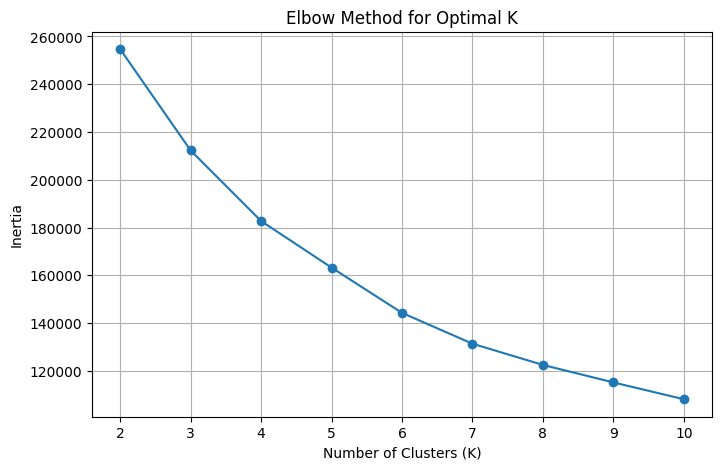

K = 2, Silhouette Score = 0.4397
K = 3, Silhouette Score = 0.2615
K = 4, Silhouette Score = 0.2703
K = 5, Silhouette Score = 0.2755
K = 6, Silhouette Score = 0.2477
K = 7, Silhouette Score = 0.2465
K = 8, Silhouette Score = 0.2300
K = 9, Silhouette Score = 0.2308
K = 10, Silhouette Score = 0.2297

Best K by silhouette score: 2

Cluster counts:
Cluster
0    32273
1    13457
Name: count, dtype: int64


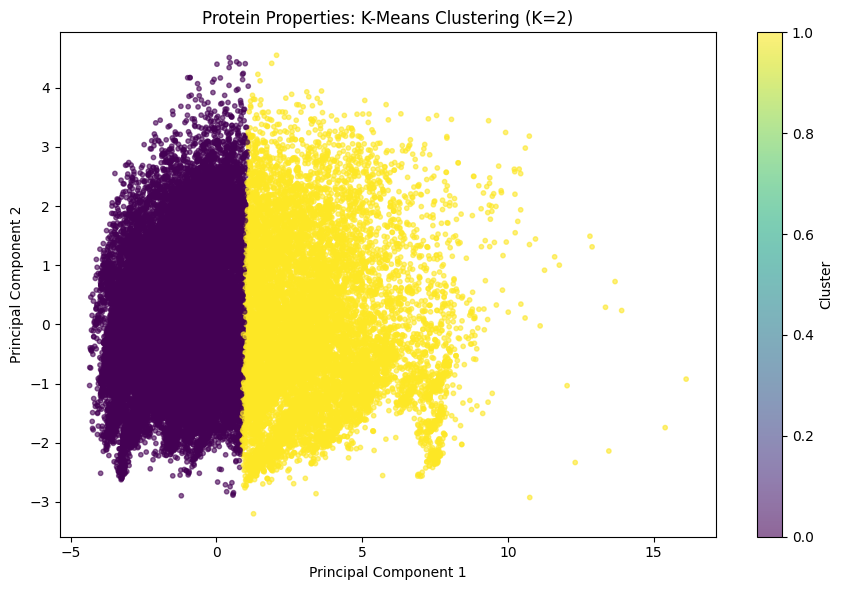

Variance explained by 2 PCA components: 79.04 %

Cluster-wise feature means:
          RMSD         F1        F2     F3       F4           F5       F6  \
Cluster                                                                     
0        7.938   7728.748  2316.444  0.298   74.372  1070846.428  108.531   
1        7.295  15010.645  4698.343  0.312  173.330  2081659.157  234.630   

               F7       F8      F9  
Cluster                             
0        3398.409   47.414  37.525  
1        5407.944  124.082  27.325  

Clustered dataset saved to: /root/.cache/kagglehub/datasets/samanemami/properties-of-protein-tertiary-structure/versions/1/protein_clusters.csv


In [2]:

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# 1. Find and load the CSV file
csv_files = glob.glob(
    os.path.join(path, "**", "*.csv"),
    recursive=True
)

if not csv_files:
    raise FileNotFoundError(
        "No CSV file found in the downloaded dataset folder."
    )

print("CSV files found:", csv_files)

df = pd.read_csv(csv_files[0])

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nFirst five rows:")
print(df.head())

# 2. Data preprocessing
# Convert columns to numeric where possible
X = df.copy()

for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Remove columns that contain no numerical data
X = X.select_dtypes(include=np.number)

# Remove rows containing missing or infinite values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

if X.shape[1] == 0:
    raise ValueError("No numeric features were found.")

print("\nData shape after preprocessing:", X.shape)

# 3. Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Elbow method to find a suitable K
inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# 5. Compare silhouette scores
# Sample rows to keep evaluation efficient
rng = np.random.RandomState(42)
sample_size = min(5000, len(X_scaled))
sample_idx = rng.choice(
    len(X_scaled), size=sample_size, replace=False
)
X_sample = X_scaled[sample_idx]

scores = {}

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)

    labels_sample = model.predict(X_sample)

    score = silhouette_score(
        X_sample,
        labels_sample
    )
    scores[k] = score
    print(f"K = {k}, Silhouette Score = {score:.4f}")

best_k = max(scores, key=scores.get)
print("\nBest K by silhouette score:", best_k)

# 6. Fit final K-Means model
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to the cleaned dataset
clustered_df = X.copy()
clustered_df["Cluster"] = cluster_labels

print("\nCluster counts:")
print(clustered_df["Cluster"].value_counts().sort_index())

# 7. Visualize clusters using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=10,
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"Protein Properties: K-Means Clustering (K={best_k})")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

print(
    "Variance explained by 2 PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# 8. Analyze the average features in each cluster
print("\nCluster-wise feature means:")
print(clustered_df.groupby("Cluster").mean().round(3))

# 9. Save results
output_file = os.path.join(path, "protein_clusters.csv")
clustered_df.to_csv(output_file, index=False)

print("\nClustered dataset saved to:", output_file)